# Bakery Operations: From Transactions to Decisions

This notebook turns the bakery's relational model into a compact business review. It evaluates sales, price realization, inventory exposure, supplier traceability, and database integrity using a fresh in-memory SQLite database.

The included dataset is deliberately small: two completed orders from one trading day. Results should be read as a **worked operational snapshot**, not as evidence of long-term trends.

## Reproducible setup

The next cell rebuilds the database from the versioned schema and fictional sample data on every run. No local `bakery.db` file is required.

In [21]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()

SCHEMA_PATH = PROJECT_ROOT / "sql" / "create_tables.sql"

SAMPLE_DATA_PATH = PROJECT_ROOT / "sql" / "insert_sample.sql"

if not SCHEMA_PATH.exists() or not SAMPLE_DATA_PATH.exists():
    raise FileNotFoundError("Run this notebook from the repository root.")

connection = sqlite3.connect(":memory:")

connection.execute("PRAGMA foreign_keys = ON;")

connection.executescript(SCHEMA_PATH.read_text(encoding="utf-8"))

connection.executescript(SAMPLE_DATA_PATH.read_text(encoding="utf-8"))

pd.options.display.float_format = "{:,.2f}".format

plt.style.use("seaborn-v0_8-whitegrid")

def query(sql: str, parameters: tuple = ()) -> pd.DataFrame:

    return pd.read_sql_query(sql, connection, params=parameters)

print("Fresh in-memory bakery database created successfully.")

Fresh in-memory bakery database created successfully.


## Model verification

Before analyzing the business, verify that the complete schema loaded and that its foreign-key relationships are internally consistent.

In [22]:
object_counts = query(

    """

    SELECT type AS object_type, COUNT(*) AS object_count

    FROM sqlite_master

    WHERE type IN ('table', 'view')

      AND name NOT LIKE 'sqlite_%'

    GROUP BY type

    ORDER BY type;

    """

)

foreign_key_violations = query("PRAGMA foreign_key_check;")

display(object_counts)

print(f"Foreign-key violations: {len(foreign_key_violations)}")

,object_type,object_count
0,table,14
1,view,2


Foreign-key violations: 0


## Trading-day snapshot

These headline indicators describe the completed orders in the sample. Revenue is derived from line items rather than stored redundantly on the order.

In [23]:
kpis = query(

    """

    SELECT

        COUNT(DISTINCT orders.order_id) AS completed_orders,

        COUNT(DISTINCT orders.customer_id) AS identified_customers,

        SUM(order_items.quantity) AS units_sold,

        ROUND(SUM(order_items.quantity * order_items.unit_price_cents) / 100.0, 2) AS revenue,

        ROUND(

            SUM(order_items.quantity * order_items.unit_price_cents)

            / 100.0 / COUNT(DISTINCT orders.order_id),

            2

        ) AS average_order_value

    FROM orders

    JOIN order_items ON order_items.order_id = orders.order_id

    WHERE orders.order_status = 'Completed';

    """

)

kpis.rename(

    columns={

        "completed_orders": "Completed orders",

        "identified_customers": "Identified customers",

        "units_sold": "Units sold",

        "revenue": "Revenue",

        "average_order_value": "Average order value",

    }

).T.rename(columns={0: "Value"})

,Value
Completed orders,2.00
Identified customers,2.00
Units sold,14.00
Revenue,59.50
Average order value,29.75


## Product performance

Revenue concentration shows which products mattered most in the sample day. Because the dataset is small, the chart is useful as a query demonstration rather than a demand forecast.

,product_name,category_name,units_sold,revenue
0,Grandma's Chocolate Cake,Cakes,1,35.00
1,French Bread,Breads,10,8.00
2,Whole Milk Carton,Beverages,1,6.50
3,Chicken Coxinha,Savories,1,5.00
4,Soda Can,Beverages,1,5.00


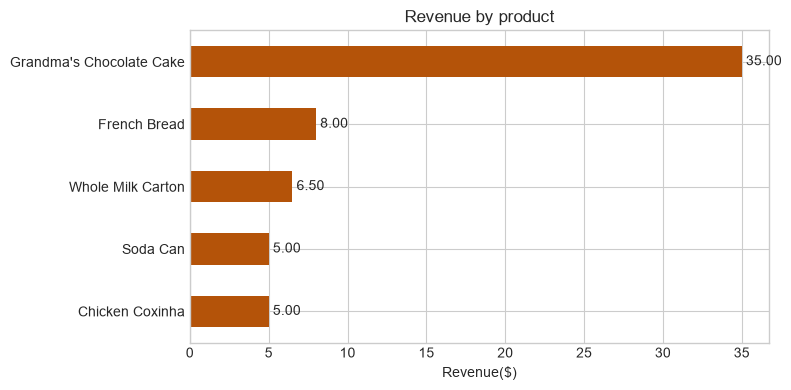

In [24]:
product_performance = query(

    """

    SELECT

        products.product_name,

        categories.category_name,

        SUM(order_items.quantity) AS units_sold,

        ROUND(SUM(order_items.quantity * order_items.unit_price_cents) / 100.0, 2) AS revenue

    FROM order_items

    JOIN orders ON orders.order_id = order_items.order_id

    JOIN products ON products.product_id = order_items.product_id

    LEFT JOIN categories ON categories.category_id = products.category_id

    WHERE orders.order_status = 'Completed'

    GROUP BY products.product_id, products.product_name, categories.category_name

    ORDER BY revenue DESC;

    """

)

display(product_performance)

axis = product_performance.sort_values("revenue").plot.barh(

    x="product_name",

    y="revenue",

    color="#B45309",

    legend=False,

    figsize=(8, 4),

)

axis.set(title="Revenue by product", xlabel="Revenue($)", ylabel="")

axis.bar_label(axis.containers[0], fmt="%.2f", padding=3)

plt.tight_layout()

plt.show()

## Price realization and transaction history

The catalog price answers “what does this product cost now?” The line-item price answers “what did this customer actually pay?” Keeping both prevents later catalog changes from rewriting history and makes discounts or overrides auditable.

In [25]:
price_realization = query(
    """

    SELECT

        products.product_name,

        products.sale_price_cents / 100.0 AS current_catalog_price,

        ROUND(

            SUM(order_items.quantity * order_items.unit_price_cents)

            / 100.0 / SUM(order_items.quantity),

            2

        ) AS average_realized_price,

        ROUND(

            100.0 * (

                SUM(order_items.quantity * order_items.unit_price_cents)

                / SUM(order_items.quantity) - products.sale_price_cents

            ) / products.sale_price_cents,

            1

        ) AS variance_from_catalog_pct

    FROM order_items

    JOIN orders ON orders.order_id = order_items.order_id

    JOIN products ON products.product_id = order_items.product_id

    WHERE orders.order_status = 'Completed'

    GROUP BY products.product_id, products.product_name, products.sale_price_cents

    ORDER BY variance_from_catalog_pct, products.product_name;

    """
)

price_realization

,product_name,current_catalog_price,average_realized_price,variance_from_catalog_pct
0,Chicken Coxinha,7.50,5.00,-33.30
1,French Bread,0.80,0.80,0.00
2,Grandma's Chocolate Cake,35.00,35.00,0.00
3,Soda Can,5.00,5.00,0.00
4,Whole Milk Carton,6.50,6.50,0.00


## Inventory position

Stock volume and replenishment policy are separate concerns. A zero balance is not automatically actionable when no minimum threshold has been configured, so the query labels that data-quality gap explicitly.

,ingredient_name,unit_of_measure,current_quantity,minimum_quantity,next_expiration_date,stock_status
0,50% Cocoa Powder,kg,0.00,0.00,NaN,Threshold not set
1,Dry Yeast,g,0.00,0.00,NaN,Threshold not set
2,Eggs,unit,0.00,0.00,NaN,Threshold not set
3,All-Purpose Flour,kg,50.00,20.00,2026-06-30,Sufficient
4,Whole Milk,liter,24.00,12.00,2025-09-25,Sufficient


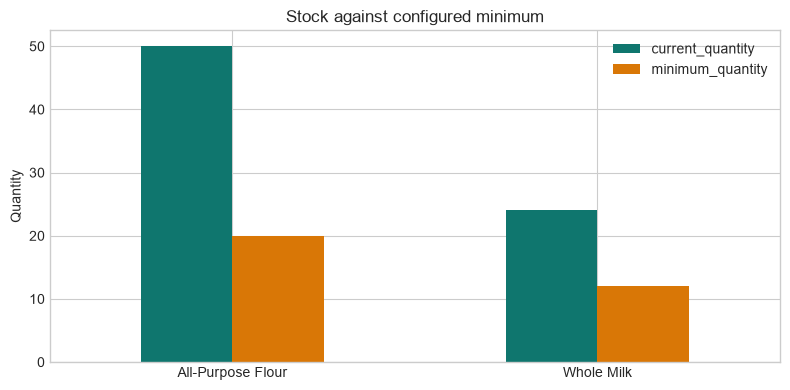

In [26]:
inventory_position = query(

    """

    SELECT

        ingredients.ingredient_name,

        ingredients.unit_of_measure,

        ingredient_stock.current_quantity,

        ingredient_stock.minimum_quantity,

        ingredient_stock.next_expiration_date,

        CASE

            WHEN ingredient_stock.minimum_quantity = 0 THEN 'Threshold not set'

            WHEN ingredient_stock.current_quantity < ingredient_stock.minimum_quantity THEN 'Reorder'

            ELSE 'Sufficient'

        END AS stock_status

    FROM ingredient_stock

    JOIN ingredients ON ingredients.ingredient_id = ingredient_stock.ingredient_id

    ORDER BY

        CASE stock_status

            WHEN 'Reorder' THEN 1

            WHEN 'Threshold not set' THEN 2

            ELSE 3

        END,

        ingredients.ingredient_name;

    """

)

display(inventory_position)

configured_thresholds = inventory_position.query("minimum_quantity > 0").set_index("ingredient_name")

axis = configured_thresholds[["current_quantity", "minimum_quantity"]].plot.bar(

    color=["#0F766E", "#D97706"],

    figsize=(8, 4),

)

axis.set(title="Stock against configured minimum", xlabel="", ylabel="Quantity")

axis.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.show()

## Shelf-life exposure

Adequate quantity does not eliminate waste risk. Using the latest transaction date as the operational snapshot, the next query measures how soon each available batch will expire.

In [27]:
expiration_exposure = query(

    """

    WITH snapshot AS (

        SELECT DATE(MAX(order_timestamp)) AS snapshot_date

        FROM orders

    )

    SELECT

        ingredients.ingredient_name,

        ingredient_batches.batch_id,

        suppliers.supplier_name,

        ingredient_batches.current_quantity,

        ingredient_batches.expiration_date,

        CAST(

            JULIANDAY(ingredient_batches.expiration_date)

            - JULIANDAY(snapshot.snapshot_date)

            AS INTEGER

        ) AS days_until_expiration,

        CASE

            WHEN ingredient_batches.expiration_date IS NULL THEN 'No expiry recorded'

            WHEN JULIANDAY(ingredient_batches.expiration_date) - JULIANDAY(snapshot.snapshot_date) <= 30 THEN 'Use first'

            ELSE 'Monitor'

        END AS action

    FROM ingredient_batches

    JOIN ingredients ON ingredients.ingredient_id = ingredient_batches.ingredient_id

    JOIN suppliers ON suppliers.supplier_id = ingredient_batches.supplier_id

    CROSS JOIN snapshot

    WHERE ingredient_batches.current_quantity > 0

    ORDER BY

        ingredient_batches.expiration_date IS NULL,

        ingredient_batches.expiration_date;

    """

)

expiration_exposure

,ingredient_name,batch_id,supplier_name,current_quantity,expiration_date,days_until_expiration,action
0,Whole Milk,3,Good Taste Dairy,24.00,2025-09-25,15,Use first
1,All-Purpose Flour,1,Flour & Co.,20.00,2026-06-30,293,Monitor
2,All-Purpose Flour,2,Flour & Co.,30.00,2026-12-31,477,Monitor


## Supplier coverage and traceability

The bridge between ingredients and suppliers supports sourcing alternatives, while each received batch preserves its actual origin. Coverage also reveals ingredients that currently depend on a single approved supplier.

In [28]:
supplier_coverage = query(

    """

    SELECT

        ingredients.ingredient_name,

        COUNT(DISTINCT ingredient_suppliers.supplier_id) AS approved_supplier_count,

        REPLACE(

            GROUP_CONCAT(DISTINCT suppliers.supplier_name),

            ',',

            ', '

        ) AS approved_suppliers,

        COUNT(DISTINCT ingredient_batches.batch_id) AS received_batch_count

    FROM ingredients

    LEFT JOIN ingredient_suppliers

        ON ingredient_suppliers.ingredient_id = ingredients.ingredient_id

    LEFT JOIN suppliers

        ON suppliers.supplier_id = ingredient_suppliers.supplier_id

    LEFT JOIN ingredient_batches

        ON ingredient_batches.ingredient_id = ingredient_suppliers.ingredient_id

       AND ingredient_batches.supplier_id = ingredient_suppliers.supplier_id

    GROUP BY ingredients.ingredient_id, ingredients.ingredient_name

    ORDER BY approved_supplier_count, ingredients.ingredient_name;

    """

)

supplier_coverage

,ingredient_name,approved_supplier_count,approved_suppliers,received_batch_count
0,50% Cocoa Powder,1,Flour & Co.,0
1,All-Purpose Flour,1,Flour & Co.,2
2,Dry Yeast,1,Flour & Co.,0
3,Eggs,1,Good Taste Dairy,0
4,Whole Milk,1,Good Taste Dairy,1


## Integrity rules as executable evidence

A portfolio schema should demonstrate what it refuses to store. The following probes attempt four invalid writes inside savepoints and confirm that database constraints reject each one without changing the analytical dataset.

In [29]:
def constraint_rejects(sql: str) -> bool:

    connection.execute("SAVEPOINT constraint_probe;")

    try:

        connection.execute(sql)

    except sqlite3.IntegrityError:

        rejected = True

    else:

        rejected = False

    finally:

        connection.execute("ROLLBACK TO constraint_probe;")

        connection.execute("RELEASE constraint_probe;")

    return rejected

constraint_probes = {

    "Negative catalog price": """

        INSERT INTO products (product_id, product_name, sale_price_cents)

        VALUES (900, 'Invalid Product', -1);

    """,

    "Unknown order status": """

        INSERT INTO orders (order_id, employee_id, order_status)

        VALUES (900, 1, 'Refunded');

    """,

    "Batch balance above received quantity": """

        INSERT INTO ingredient_batches (

            batch_id, ingredient_id, supplier_id, received_quantity, current_quantity

        ) VALUES (900, 101, 1, 1, 2);

    """,

    "Second open till for one employee": """

        INSERT INTO till_sessions (

            session_id, employee_id, opening_timestamp, initial_balance_cents

        ) VALUES (900, 1, '2025-09-10 09:00:00', 10000);

    """,

}

constraint_results = pd.DataFrame(

    {

        "rule": constraint_probes.keys(),

        "invalid_write_rejected": [

            constraint_rejects(sql) for sql in constraint_probes.values()

        ],

    }

)

constraint_results

,rule,invalid_write_rejected
0,Negative catalog price,True
1,Unknown order status,True
2,Batch balance above received quantity,True
3,Second open till for one employee,True


## Executive findings

1. **Revenue is concentrated in cake for this snapshot.** Chocolate cake contributes 35.00 of 59.50 in completed-order revenue (58.8%). More days are required before treating that mix as representative demand.

2. **One transaction needs commercial explanation.** Chicken Coxinha realized 5.00 against a current catalog price of 7.50, a 33.3% difference. The historical price is preserved correctly, but the business should distinguish an approved promotion from an unplanned override.

3. **Milk should be consumed first.** Its 24-liter balance is above the 12-liter minimum, yet its available batch expires 15 days after the snapshot date. Quantity alone would miss this exposure.

4. **Replenishment policy is incomplete.** Dry yeast, eggs, and cocoa have zero recorded stock and zero minimum thresholds. Those rows need configured reorder points before an alert can be meaningful.

5. **Sourcing is concentrated.** Every modeled ingredient has one approved supplier. Qualifying alternatives would reduce continuity risk for production-critical inputs.

### Recommended next actions

- Confirm and document the Coxinha price variance.

- Apply first-expire, first-out handling to the milk batch.

- Define minimum stock levels for every production ingredient.

- Add at least one alternate supplier for critical ingredients.

- Collect several months of sales, receipts, production, and waste events before forecasting demand or profitability.

## Scope and analytical limits

This notebook demonstrates relational analysis and operational reasoning; it does not estimate long-term demand, margin, or waste.

The current model lacks purchase costs, production runs, stock movements, and waste events. Those facts are required for product margin, recipe consumption variance, yield, and spoilage analysis. The sample also covers only one day, so weekday patterns, seasonality, customer retention, and forecasting would be statistically unsupported.

A production-ready analytical extension should add deterministic multi-month data and preserve the operational database as the source of truth, with DuckDB or Parquet used for larger analytical workloads.